<h2 style="font-weight:600;color:#4f7a9b">Empirical Evaluation of the Impact of k-means Initialization</h2>

> **First plot** :<br/>
    Shows inertia versus increasing number of  initializations, for four combinations of models(KMeans & MiniBatchKMeans) and initialization strategies (random & k-means++)
>
> **Second plot** :<br/>
    Demonstrates only the MiniBatchKMeans estimator, with `random` initialization strategy and just one initialization. This leads to bad convergence, with *estimated* centers stuck between *actual* clusters.

Evaluation of KMeans with k-means++
Evaluation of KMeans with random
Evaluation of MiniBatchKMeans with k-means++
Evaluation of MiniBatchKMeans with random


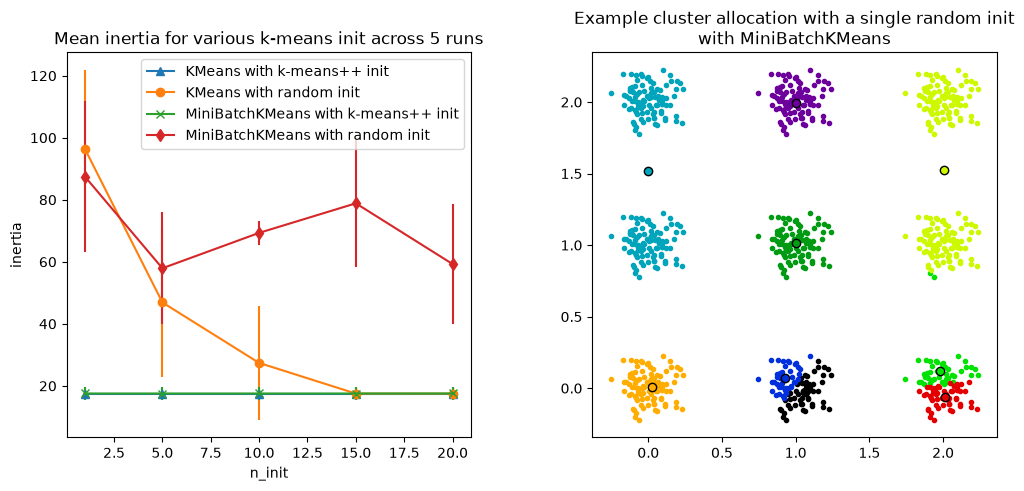

In [15]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import RandomState

from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.utils import shuffle, check_random_state

random_state = RandomState(0)

# ##############################################
#               VARIABLES USED
# ##############################################
# n_runs        Number of runs for each strategy
# n_init_range  Number of initializations of the estimator

# Number of runs (with randomly generated dataset) for each strategy so as
# to be able to compute an estimate of the standard deviation.
n_runs = 5

# k-means models can do several random inits so as to be able to trade
# CPU time for convergence robustness.
n_init_range = np.array([1, 5, 10, 15, 20])

# Datasets generation parameters
n_samples_per_center = 100
grid_size = 3
scale = 0.1
n_clusters = grid_size**2


def make_data(random_state: RandomState, n_samples_per_center: int, grid_size: int, scale: float):
    random_state = check_random_state(random_state)
    centers = np.array([[i, j] for i in range(grid_size) for j in range(grid_size)])
    n_clusters_true, n_features = centers.shape

    noise = random_state.normal(
        loc=0,
        scale=scale,
        size=(n_samples_per_center, centers.shape[1]),
    )

    X = np.concatenate([c + noise for c in centers])
    y = np.concatenate([[i] * n_samples_per_center for i in range(n_clusters_true)])

    return shuffle(X, y, random_state=random_state)


# ##########################################################
# PART 1: Quantitative evaluation of various init methods
# ##########################################################

# plt.figure()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
fig.subplots_adjust(wspace=0.3)
plots = []
legends = []

# The four combinations of estimators and initialization strategies in the form:
# (estimator, init, params, format)
cases = [
    (KMeans, "k-means++", {}, "^-"),
    (KMeans, "random", {}, "o-"),
    (MiniBatchKMeans, "k-means++", {"max_no_improvement": 3}, "x-"),
    (MiniBatchKMeans, "random", {"max_no_improvement": 3, "init_size": 500}, "d-"),
]

# Loop over each combination of estimator and init method.
for estimator, init, params, format in cases:
    print(f"Evaluation of {estimator.__name__} with {init}")
    inertia = np.empty((len(n_init_range), n_runs))

    # For each combination perform 5 runs.
    for run_id in range(n_runs):
        X, y = make_data(run_id, n_samples_per_center, grid_size, scale)

        # Run the estimator/init combination five times with different n_init (1, 5, 10, 15, 20)
        for i, n_init in enumerate(n_init_range):
            km = estimator(
                n_clusters=n_clusters,
                init=init,
                random_state=run_id,
                n_init=n_init,
                **params,
            ).fit(X)
            inertia[i, run_id] = km.inertia_

    p = ax1.errorbar(
        n_init_range,
        inertia.mean(axis=1),
        inertia.std(axis=1),
        fmt=format,
    )

    plots.append(p[0])
    legends.append(f"{estimator.__name__} with {init} init")

ax1.set_xlabel("n_init")
ax1.set_ylabel("inertia")
ax1.legend(plots, legends)
ax1.set_title(f"Mean inertia for various k-means init across {n_runs} runs")

# ##########################################################
# PART 2: Qualitative visual inspection of the convergence
# ##########################################################

X, y = make_data(random_state, n_samples_per_center, grid_size, scale)
km = MiniBatchKMeans(
    n_clusters=n_clusters,
    init="random",
    n_init=1,
    random_state=random_state,
).fit(X)

for k in range(n_clusters):
    my_members = km.labels_ == k
    color = cm.nipy_spectral(float(k) / n_clusters, 1)
    ax2.plot(X[my_members, 0], X[my_members, 1], ".", c=color)
    cluster_center = km.cluster_centers_[k]
    ax2.plot(
        cluster_center[0],
        cluster_center[1],
        "o",
        markerfacecolor=color,
        markeredgecolor="k",
        markersize=6,
    )
    ax2.set_title("Example cluster allocation with a single random init\nwith MiniBatchKMeans")

plt.show()